![](../../logos/gerics.png)

# GERICS Factsheet Africa
## Program to create Tabelle 1


**Katharina Bülow**, Climate Service Center Germany (GERICS), Helmholtz-Zentrum hereon GmbH, Email: katharina.buelow@hereon.de

In [54]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [55]:
import os
from glob import glob
from tools_indices_table import *
import matplotlib as mpl
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import colormaps
from matplotlib import pyplot as plt
from matplotlib.colors import ListedColormap

Um die Tabelle zu erstellen, benötigt man 2 gleiche *DataFrames*, einen mit den Daten und einen mit der Information zur Robustheit.

In [56]:
# Directories need to be defined
database='/work/ch0636/g300047/cicles/'
era5_dir = os.path.join(database, 'climate_fact_data/spavg_era5/')
data_dir=os.path.join(database, 'climate_fact_data/spavg_afr22/')
plot_dir = os.path.join(database,'factsheet_africa/PLOTS/Table_rb/')

if not os.path.exists(plot_dir):
    os.makedirs(plot_dir)   


In [58]:
# Chose Region:
region = "Burkina Faso"
#region = "Togo"
#region = "Ivory Coast"
method = "absolute"

# Hier kann auswählen ob man Min/Max oder Percentile bzw Mean oder Median verwenden möchte

if method == "pro":
    fixh= "time-mean_ensemble-median"
    fixmh = "time-mean_ensemble-p5-p95"
    fix = "time-mean_ensemble-diff-frac-median"
    fixm = "time-mean_ensemble-diff-frac-p5-p95"
    fixr = "ensemble-robustness"
else:
    fixh= "time-mean_ensemble-median"
    fixmh = "time-mean_ensemble-p5-p95"
    fix = "time-mean_ensemble-diff-median"
    fixm = "time-mean_ensemble-diff-p5-p95"
    fixr = "ensemble-robustness"

frequency = "year"
index_season = ["TG", "RRm", "DD", "FG"]


index = [
    "TG",
    "TN",
    "TX",
    #"TR", # fehlt bei era5
    "TR26",
    "SU35",
    "SU40",
    "RRm",
    "DD",
    "RR1",
    "R20mm",
    #"PRCPTOT",
    "FG",
]

region_for_plot=region.replace(" ", "_")
plotname = "Table_" + region_for_plot + "_median_300.png"
plot_output = os.path.join(plot_dir, plotname)

In [59]:
df_out = pd.DataFrame()

for ind in index:
    # Jährlich
    # Einlesen der Beobachtungen in der 1. Spalte
    fileo = (
        era5_dir
        +"/"
        + ind
        + "/"
        + ind
        + "_"
        + frequency
        + "_ref_time-mean.csv"
    )
    dft = read_obs(fileo, ind, frequency, 7,region)
    filess = glob.glob(
        data_dir
        + "/"
        + ind
        + "/"
        + ind
        + "_"
        + frequency
        + "_2"
        + "*"
        + fix
        + ".csv"
    )

    dfmm = minmax(filess, region, 7, method)
    dfmm_=dfmm.copy()
    for rcp in ("rcp26", "rcp85"):
        for time_period in ("2031_2060", "2069_2098"):  
            dfmm_ = rename(dfmm_, ind, frequency, fixh, fixmh, fix, fixm, fixr, rcp, time_period)

    dft = time_slice(filess, region, dft, 7,ind,fixh)
    dft_=dft.copy()
    for rcp in ("rcp26", "rcp85"):
        for time_period in ("2031_2060", "2069_2098"):
            dft_ = rename(dft_, ind, frequency, fixh, fixmh,fix, fixm, fixr, rcp, time_period)     
    # Hier werden alle unter einander geschrieben:
    df_out = pd.concat([df_out, dft_, dfmm_], axis=0)

# Index setzen
df_out_ = df_out.copy()
df_index_ = df_out_.set_index(["Index"])
df_index__ = df_index_.replace("-0.0", "0")
df_index = df_index__.replace("0.0", "0")

/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/INDICES-TABLE/tools_indices_table.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sel[c] = sel[c] - 273.15
/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/INDICES-TABLE/tools_indices_table.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  sel[c] = sel[c] - 273.15
/home/g/g300047/SCRIPTS/github/factsheet_africa/Notebooks/INDICES-TABLE/tools_indices_table.py:36: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice

Nun benötigen wir genau denselben Dataframe, um die Robustheit in Farbe darzustellen. Min/Max
haben keine Robustheit und werden in Hellgrau hervorgehoben. Min/Max wurde für die Beobachtungen nicht berechnet: daher leer und weiß, sodass die Robustheit hier auf NaN gesetzt werden muss.

In [60]:
df_r = pd.DataFrame()

for ind in index:
    # Beobachtung hat keine Robustheit
    dft, dfmm = obs_robust(ind, 7)
    # euro-cordex:
    files = glob.glob(
        data_dir
        + ind
        + "/"
        + ind
        + "_"
        + frequency
        + "*"
        + fixr
        + ".csv"
    )
    
    dft = time_slice(files, region, dft, 7, ind,fixh)
    dfmm = time_slice_mm(files)
    dft_=dft.copy()
    dfmm_=dfmm.copy()
    for rcp in ("rcp26", "rcp85"):
        for time_period in ("2031_2060", "2069_2098"):
            dft_= rename(dft_, ind, frequency, fixh, fixmh,fix, fixm, fixr, rcp, time_period)
            dfmm_= rename(dfmm_, ind, frequency, fixh, fixmh,fix, fixm, fixr, rcp, time_period)

    # here everything will be written below each other
    df_r = pd.concat([df_r, dft_, dfmm_], axis=0)
    
# set index
dfr = df_r.copy()
df_rob = dfr.set_index(["Index"])


## Bedeutung der Zahlen für die Robustheit:

* Threshold für Änderung=2/3
* Threshold für Signifikanz=0.5

**2** robust 2/3 in eine Richtung und 0.5 Signifikant

**1** trend 2/3 in einen Richtung

**0** unklar +/- aber 0.5 sind significant

**NaN** no change weniger als 2/3 und weniger als 1/2 signifikant




0 wird später für NaN benötigt.
E-OBS (Beobachtungen) und Min/Max haben keine Robustheit, daher werden sie auf NaN gesetzt.
Allerdings, wenn NaN in der Heatmap ist, fehlt der Wert ebenfalls, dies ist Absichtlich für E-OBS.
Für Min/MAX wird deshalb das NaN durch 0 ersetzt.
NaN wurde eingelesen.

In [61]:
df_robn_ = df_rob.replace("nan", 0)

## Now chose if you like the color for Robustness grey or red-blue
## jetzt plotten:


In [70]:
# Die Robustheitsparameter werden einmal überschrieben,
# weil die Arbeit mit der Farbskala bei einheitlichen Abständen einfacher ist.
# Kein wissenschaftlicher Grund, nur um das Farbdesign zu vereinfachen.
# NaN in Weiß.


# blue-red:
# Robustness Colors
color="blue_red"
plotname = "Table_" + region_for_plot + "_median_300_red_blue.png"
# Define colorrange for blue-red (7 bins: -3 to 3)
colorrange = range(len(cmap_dict))

df_rob_ = df_robn_.replace(
    {
        "-2.0": "-3",
        "-1.0": "-2",
        "-0.5": "-1",
        0: "0",
        "0.0": "0",
        "0.5": "1",
        "1.0": "2",
        "2.0": "3",
    }
)

for i in df_rob_.columns:
    df_rob_[i] = df_rob_[i].astype(float)

cmap = ListedColormap([cmap_dict[i] for i in [-3, -2, -1, 0, 1, 2, 3]])
# Use the already defined 'bounds' variable from the notebook context
bounds = [-3.5, -2.5, -1.5, -0.5, 0.5, 1.5, 2.5, 3.5]
# Um genau eine Farbbox pro ganzzahligem Interval zu erhalten:

norm = mpl.colors.BoundaryNorm(bounds, len(colorrange))

In [16]:
# Die Robustheitsparameter werden einmal überschrieben,
# weil die Arbeit mit der Farbskala bei einheitlichen Abständen einfacher ist.
# Kein wissenschaftlicher Grund, nur um das Farbdesign zu vereinfachen.
# NaN in Weiß.

# Farben für die Robustheit festlegen:
# grau:
color="grey"
cmap_dict = {0: "#f7f7f7", 1: "#cccccc", 2: "#969696", 3: "#636363"}

plotname = "Table_" + region_for_plot + "_median_300_grey.png"

colorrange = range(len(list(cmap_dict.keys())))
cmap = ListedColormap([cmap_dict[i] for i in [0, 1, 2, 3]])
bounds = np.array(range(len(list(cmap_dict.keys())) + 1)) - 0.5

# Um genau eine Farbbox pro ganzzahligem Interval zu erhalten:

norm = mpl.colors.BoundaryNorm(bounds, len(colorrange))

df_robn_ = df_robn_.replace(
    {
        "-2.0": "3",
        "-1.0": "2",
        "-0.5": "1",
        0: "0",
        "0.0": "0",
        "0.5": "1",
        "1.0": "2",
        "2.0": "3",
    }
)

for i in df_rob_.columns:
    df_rob_[i] = df_rob_[i].astype(float)



In [71]:
#rename index for plotting
df_rob_ = rename_index(df_rob_)
df_index = rename_index(df_index)


In [72]:
# rename columns for plotting
df_index_plot_ = df_index.copy()
df_rob_plot_ = df_rob_.copy()
df_index_plot=rename_columns(df_index_plot_)
df_rob_plot=rename_columns(df_rob_plot_)


Plot saved:  /work/ch0636/g300047/cicles/factsheet_africa/PLOTS/Table_rb/Table_Burkina_Faso_median_300.png


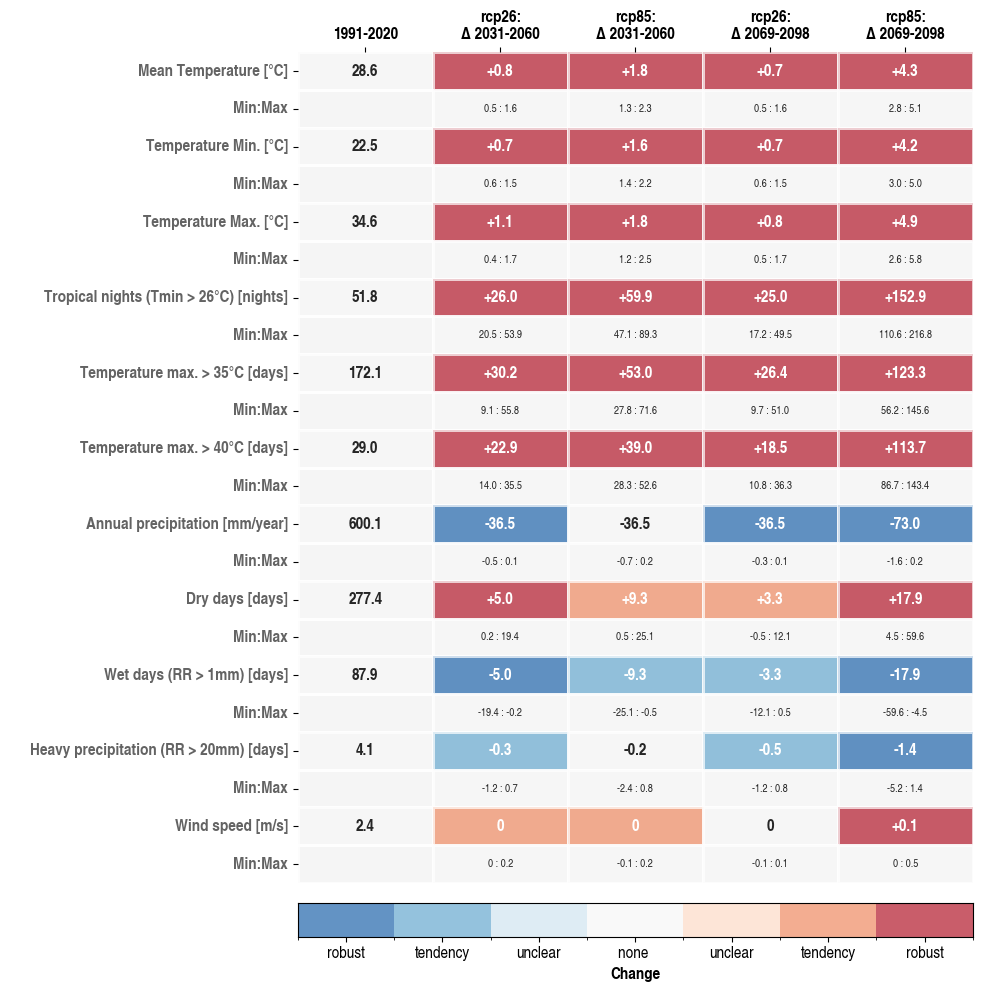

In [74]:
# Plotten:
# komischerweise muss ich dies 2 mal ausführen um auch die Schrift zubekommen, die ich will.


plt.rcParams["font.family"] = "Nimbus Sans Narrow"

colorrange = range(len(list(cmap_dict.keys())))

# annot ist df_ der Wert des Indices, die farbe ist die robustheit dfr_
size = (10, 13)
fig, ax = plt.subplots(figsize=size)
# plt.rcParams['font.family'] = 'Nimbus Sans Narrow'
fig.subplots_adjust(right=0.8)

ax = sns.heatmap(
    df_rob_plot,
    annot=df_index_plot,
    fmt="",
    cmap=cmap,
    norm=norm,
    cbar_kws={
        "orientation": "horizontal",
        "pad": 0.02,
        #"label": "decrease                               increase ",
        "label": "Change"
    },
    linewidths=1,
    alpha=0.7,
)
ax.set_facecolor("whitesmoke")
ax.figure.axes[-1].xaxis.label.set_size(12)  # größe der Schrift der colorbar legende
ax.figure.axes[-1].xaxis.label.set_fontweight("bold")


for label in ax.get_yticklabels():
    lc = label_color(label.get_text())
    label.set_color(lc)
    if label.get_text() != "Min : Max":
        label.set_weight("bold")
        label.set_size(12)
    else:
        label.set_size(8)


# Das ist ein Workaround, da 'Min-Max' in der ersten Spalte ein NaN hat und ich es nicht entfernen konnte.

m = 0
for i in range(len(df_index_plot)):
    font_sizes = annotate_row(df_index_plot.index[i])
    font_weight = annotate_row_weight(df_index_plot.index[i])

    if i % 2 == 1:
        end =4  # Min:Max rows
    else:
        end =5  # data rows
        # add '+' only for column index 3 (4th column) numeric positives
        try:
            for k in range(1, end):
                v = df_index_plot.iat[i, k]
                fv = float(v)
                if fv > 0 and not str(v).startswith('+'):
                    df_index_plot.iat[i, k] = f'+{fv}'
        except (ValueError, TypeError):
            pass
    

    for j in range(end):
        ax.texts[m].set_fontsize(font_sizes[j])
        ax.texts[m].set_fontweight(font_weight[j])
        # This would be nice, but does not work with naN
        # ax.texts[i * len(df_index.columns) + j].set_fontsize(font_sizes[j])
        m = m + 1

# Colorbar manipulieren:
if color == "blue_red":
    c_bar = ax.collections[0].colorbar
    c_bar.set_ticks([-3, -2, -1, 0, 1, 2, 3])
    # Hier nochmal gucken was man hinneinschreiben möchte
    c_bar.set_ticklabels(
    ["robust", "tendency", "unclear", "none ", "unclear", "tendency", "robust"],
    fontsize=12
    )
else:
    c_bar = ax.collections[0].colorbar
    c_bar.set_ticks([0, 1, 2, 3])
    c_bar.set_ticklabels(
    ["none ", "unclear", "tendency", "robust"],
    fontsize=12
    )
ax.xaxis.tick_top()  # x axis on top
ax.xaxis.set_label_position("top")
ax.set_ylabel(" ")
# ax.set_title(ort, color="k", fontsize=18)
plt.yticks(rotation=0)  # , fontsize=12)
plt.xticks(rotation=0, fontsize=12, fontweight="bold")

# spine draws the box around the colorbar
for spine in ax.collections[0].colorbar.ax.spines.values():
    spine.set_visible(True)  # show the border of the colorbar
# save plot:
# Ensure plot_output exists; use provided variables if available
try:
    _ = plot_output  # raises NameError if not defined
except NameError:
    # Construct plot_output from plot_dir and plotname or reasonable defaults
    pd_ = plot_dir if 'plot_dir' in globals() else './'
    pn_ = plotname if 'plotname' in globals() else (
        f"Table_{region_for_plot}_median_grey_1200_update.png" if 'region_for_plot' in globals() else "plot.png"
    )
    plot_output = os.path.join(pd_, pn_)

fig.savefig(plot_output, dpi=300, bbox_inches="tight")

print("Plot saved: ", plot_output)